# Notebook bài tập Deep Learning: Logistic Regression và Computation Graph
Chạy lần lượt các cell trong Anaconda Jupyter Notebook.

Cài thư viện nếu cần (Anaconda Prompt): `conda install numpy matplotlib` và `pip install torch`.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=6, suppress=True)

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def bce_each(y, p):
    p = np.clip(p, 1e-12, 1-1e-12)
    return -(y*np.log(p) + (1-y)*np.log(1-p))

def metrics(x, y, w, b):
    z = w*x + b
    p = sigmoid(z)
    losses = bce_each(y, p)
    return z, p, losses, losses.mean(), np.mean((p-y)*x), np.mean(p-y)


## Bài 1 — Phân loại giới tính trẻ sơ sinh
Quy ước theo bảng trong đề: Nữ=0, Nam=1. Mô hình `z=theta0+theta1*x`, `y_hat=sigmoid(z)`.


In [2]:
x1 = np.array([2.4, 3.3, 3.2, 2.5], float)
y1 = np.array([0, 1, 1, 0], float)
alpha = 0.2
theta0, theta1 = 0.5, 0.5

def metrics_b1(x, y, theta0, theta1):
    z = theta0 + theta1*x
    p = sigmoid(z)
    loss = bce_each(y, p)
    return z, p, loss, loss.mean(), np.mean(p-y), np.mean((p-y)*x)

z, p, loss, J, g0, g1 = metrics_b1(x1, y1, theta0, theta1)
print("i | x | y | z | y_hat | BCE")
for i in range(len(x1)):
    print(i+1, x1[i], int(y1[i]), f"{z[i]:.6f}", f"{p[i]:.6f}", f"{loss[i]:.6f}")
print(f"J={J:.6f}; dJ/dtheta0={g0:.6f}; dJ/dtheta1={g1:.6f}")


i | x | y | z | y_hat | BCE
1 2.4 0 1.700000 0.845535 1.867786
2 3.3 1 2.150000 0.895669 0.110185
3 3.2 1 2.100000 0.890903 0.115520
4 2.5 0 1.750000 0.851953 1.910224
J=1.000929; dJ/dtheta0=0.371015; dJ/dtheta1=0.866441


In [3]:
# Bài 1(d,e): hai bước Gradient Descent, cập nhật đồng thời
history1 = [(theta0, theta1, metrics_b1(x1,y1,theta0,theta1)[3])]
for step in range(2):
    z,p,loss,J,g0,g1 = metrics_b1(x1,y1,theta0,theta1)
    new0 = theta0 - alpha*g0
    new1 = theta1 - alpha*g1
    theta0, theta1 = new0, new1
    history1.append((theta0,theta1,metrics_b1(x1,y1,theta0,theta1)[3]))
    print(f"Sau bước {step+1}: theta0={theta0:.6f}, theta1={theta1:.6f}, loss={history1[-1][2]:.6f}")
print("So sánh loss:", history1)


Sau bước 1: theta0=0.425797, theta1=0.326712, loss=0.843619
Sau bước 2: theta0=0.366912, theta1=0.197160, loss=0.758527
So sánh loss: [(0.5, 0.5, np.float64(1.0009285765038043)), (np.float64(0.4257970253714919), np.float64(0.3267118747699186), np.float64(0.8436193648690764)), (np.float64(0.36691163284085015), np.float64(0.19715952379817772), np.float64(0.7585267332389269))]


x=2.8 kg, P(Nam)=0.714830, nhãn=Nam (1)
x=3.5 kg, P(Nam)=0.742111, nhãn=Nam (1)


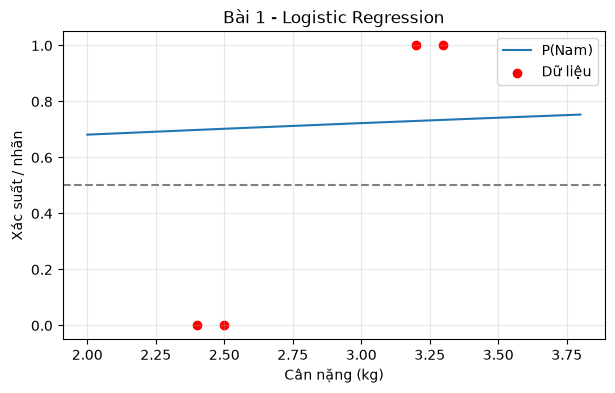

In [4]:
# Bài 1(g): dự đoán cân nặng 2.8 kg và 3.5 kg sau hai lần cập nhật
for xv in [2.8, 3.5]:
    prob = sigmoid(theta0 + theta1*xv)
    print(f"x={xv} kg, P(Nam)={prob:.6f}, nhãn={'Nam (1)' if prob>=0.5 else 'Nữ (0)'}")

# Minh họa sigmoid và dữ liệu
xx = np.linspace(2.0, 3.8, 300)
plt.figure(figsize=(7,4))
plt.plot(xx, sigmoid(theta0+theta1*xx), label="P(Nam)")
plt.scatter(x1, y1, color="red", label="Dữ liệu")
plt.axhline(.5, linestyle="--", color="gray")
plt.xlabel("Cân nặng (kg)"); plt.ylabel("Xác suất / nhãn")
plt.title("Bài 1 - Logistic Regression"); plt.grid(True, alpha=.3); plt.legend(); plt.show()


**Công thức gradient và đồ thị tính toán Bài 1**

Với `p=sigmoid(z)`, `z=theta0+theta1*x`, BCE cho một mẫu có `dL/dz=p-y`. Do đó `dJ/dtheta0=mean(p-y)` và `dJ/dtheta1=mean((p-y)*x)`. Forward: `x, theta0, theta1 → z → sigmoid → p → BCE`. Backward: `L → p → z → theta0, theta1`.


## Bài 2 — Dự đoán đánh giá phim
Dùng chuẩn hóa `x_norm=(x-130)/50`, Good=1, Bad=0; khởi tạo `w=0, b=0`, `alpha=0.2`.


i | phút | y | x_norm
1 132 1 0.040
2 141 1 0.220
3 88 0 -0.840
4 154 1 0.480
5 151 1 0.420
6 102 0 -0.560
7 119 0 -0.220
8 106 0 -0.480
9 102 0 -0.560
10 143 1 0.260
11 76 0 -1.080
12 168 1 0.760
13 94 0 -0.720
14 186 1 1.120


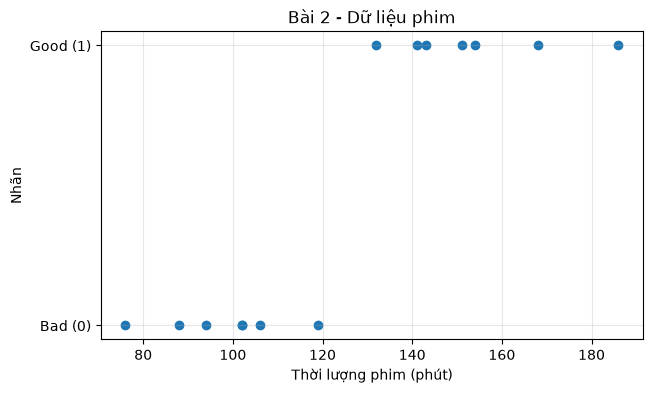


Tại khởi tạo:
1 x_norm=0.040 z=0.000000 p=0.500000 BCE=0.693147
2 x_norm=0.220 z=0.000000 p=0.500000 BCE=0.693147
3 x_norm=-0.840 z=0.000000 p=0.500000 BCE=0.693147
4 x_norm=0.480 z=0.000000 p=0.500000 BCE=0.693147
5 x_norm=0.420 z=0.000000 p=0.500000 BCE=0.693147
6 x_norm=-0.560 z=0.000000 p=0.500000 BCE=0.693147
7 x_norm=-0.220 z=0.000000 p=0.500000 BCE=0.693147
8 x_norm=-0.480 z=0.000000 p=0.500000 BCE=0.693147
9 x_norm=-0.560 z=0.000000 p=0.500000 BCE=0.693147
10 x_norm=0.260 z=0.000000 p=0.500000 BCE=0.693147
11 x_norm=-1.080 z=0.000000 p=0.500000 BCE=0.693147
12 x_norm=0.760 z=0.000000 p=0.500000 BCE=0.693147
13 x_norm=-0.720 z=0.000000 p=0.500000 BCE=0.693147
14 x_norm=1.120 z=0.000000 p=0.500000 BCE=0.693147
J=0.693147, dw=-0.277143, db=0.000000


In [5]:
x_movie = np.array([132,141,88,154,151,102,119,106,102,143,76,168,94,186], float)
y_movie = np.array([1,1,0,1,1,0,0,0,0,1,0,1,0,1], float)
xn = (x_movie-130)/50
print("i | phút | y | x_norm")
for i in range(len(xn)): print(i+1, int(x_movie[i]), int(y_movie[i]), f"{xn[i]:.3f}")

plt.figure(figsize=(7,4))
plt.scatter(x_movie,y_movie)
plt.yticks([0,1],["Bad (0)","Good (1)"])
plt.xlabel("Thời lượng phim (phút)"); plt.ylabel("Nhãn")
plt.title("Bài 2 - Dữ liệu phim"); plt.grid(True,alpha=.3); plt.show()

w,b,alpha = 0.0,0.0,0.2
z,p,loss,J,dw,db = metrics(xn,y_movie,w,b)
print("\nTại khởi tạo:")
for i in range(len(xn)): print(i+1, f"x_norm={xn[i]:.3f}", f"z={z[i]:.6f}", f"p={p[i]:.6f}", f"BCE={loss[i]:.6f}")
print(f"J={J:.6f}, dw={dw:.6f}, db={db:.6f}")


In [6]:
# Bài 2(e): hai lần cập nhật batch gradient descent
history2=[]
for step in range(3):
    z,p,loss,J,dw,db = metrics(xn,y_movie,w,b)
    history2.append((w,b,J,dw,db))
    print(f"Trước cập nhật bước {step}: w={w:.6f}, b={b:.6f}, J={J:.6f}, dw={dw:.6f}, db={db:.6f}")
    if step < 2:
        w_new, b_new = w-alpha*dw, b-alpha*db
        w,b = w_new,b_new
print("Tham số sau 2 bước:", f"w={w:.6f}, b={b:.6f}")


Trước cập nhật bước 0: w=0.000000, b=0.000000, J=0.693147, dw=-0.277143, db=0.000000
Trước cập nhật bước 1: w=0.055429, b=0.000000, J=0.677941, dw=-0.271549, db=-0.001148
Trước cập nhật bước 2: w=0.109738, b=0.000230, J=0.663341, dw=-0.266079, db=-0.002215
Tham số sau 2 bước: w=0.109738, b=0.000230


In [7]:
# Bài 2(f): xác suất phim 125 và 160 phút
for duration in [125,160]:
    xscaled=(duration-130)/50
    print(duration, "phút:", f"P(Good)={sigmoid(w*xscaled+b):.6f}")

# Bài 2(g): dự đoán, confusion matrix, Accuracy/Precision/Recall/F1
z,p,loss,J,_,_ = metrics(xn,y_movie,w,b)
ypred=(p>=0.5).astype(int)
for i in range(len(x_movie)):
    print(f"{i+1:2d}: {x_movie[i]:.0f} phút, y={int(y_movie[i])}, p={p[i]:.6f}, dự đoán={ypred[i]}")
TP=int(np.sum((y_movie==1)&(ypred==1)))
TN=int(np.sum((y_movie==0)&(ypred==0)))
FP=int(np.sum((y_movie==0)&(ypred==1)))
FN=int(np.sum((y_movie==1)&(ypred==0)))
print("Confusion matrix [ [TP,FN], [FP,TN] ]:")
print(np.array([[TP,FN],[FP,TN]]))
accuracy=(TP+TN)/len(y_movie)
precision=TP/(TP+FP) if TP+FP else 0
recall=TP/(TP+FN) if TP+FN else 0
f1=2*precision*recall/(precision+recall) if precision+recall else 0
print(f"Accuracy={accuracy:.4f}; Precision={precision:.4f}; Recall={recall:.4f}; F1={f1:.4f}")


125 phút: P(Good)=0.497314
160 phút: P(Good)=0.516512
 1: 132 phút, y=1, p=0.501155, dự đoán=1
 2: 141 phút, y=1, p=0.506093, dự đoán=1
 3: 88 phút, y=0, p=0.477029, dự đoán=0
 4: 154 phút, y=1, p=0.513223, dự đoán=1
 5: 151 phút, y=1, p=0.511578, dự đoán=1
 6: 102 phút, y=0, p=0.484699, dự đoán=0
 7: 119 phút, y=0, p=0.494022, dự đoán=0
 8: 106 phút, y=0, p=0.486892, dự đoán=0
 9: 102 phút, y=0, p=0.484699, dự đoán=0
10: 143 phút, y=1, p=0.507190, dự đoán=1
11: 76 phút, y=0, p=0.470462, dự đoán=0
12: 168 phút, y=1, p=0.520896, dự đoán=1
13: 94 phút, y=0, p=0.480315, dự đoán=0
14: 186 phút, y=1, p=0.530745, dự đoán=1
Confusion matrix [ [TP,FN], [FP,TN] ]:
[[7 0]
 [0 7]]
Accuracy=1.0000; Precision=1.0000; Recall=1.0000; F1=1.0000


x_norm boundary=-0.002092; thời lượng boundary=129.895 phút


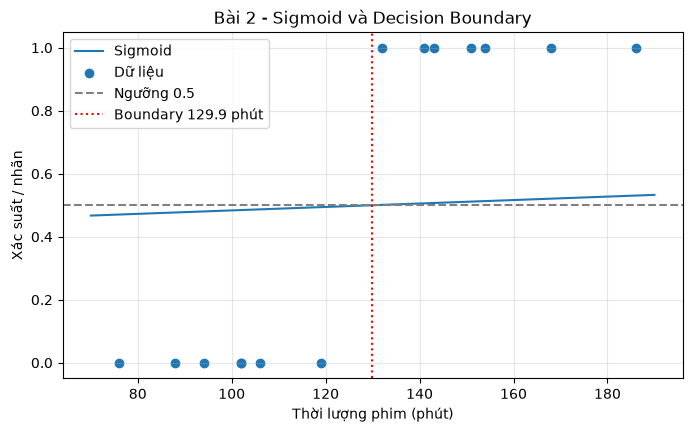

In [8]:
# Bài 2(h): sigmoid và decision boundary tại ngưỡng 0.5
# sigmoid(z)=0.5 khi z=0, nên x_norm*=-b/w; thời lượng gốc = 130+50*x_norm*
if abs(w)>1e-12:
    xb_norm=-b/w
    xb=130+50*xb_norm
    print(f"x_norm boundary={xb_norm:.6f}; thời lượng boundary={xb:.3f} phút")
else:
    xb=None
xx=np.linspace(70,190,400)
pp=sigmoid(w*((xx-130)/50)+b)
plt.figure(figsize=(8,4.5))
plt.plot(xx,pp,label="Sigmoid")
plt.scatter(x_movie,y_movie,label="Dữ liệu")
plt.axhline(.5,linestyle="--",color="gray",label="Ngưỡng 0.5")
if xb is not None: plt.axvline(xb,linestyle=":",color="red",label=f"Boundary {xb:.1f} phút")
plt.xlabel("Thời lượng phim (phút)"); plt.ylabel("Xác suất / nhãn")
plt.title("Bài 2 - Sigmoid và Decision Boundary"); plt.ylim(-.05,1.05)
plt.grid(True,alpha=.3); plt.legend(); plt.show()


**Gradient Bài 2:** `dJ/dw=mean((y_hat-y)*x_norm)`; `dJ/db=mean(y_hat-y)`. Forward: `x_norm → w*x_norm+b → sigmoid → y_hat → BCE`. Backward truyền từ loss về `w,b`.


w sau 1000 vòng=7.670320; b=0.768547
Loss cuối trước cập nhật cuối=0.066288
Loss sau cập nhật cuối=0.066252
Loss sau 2 bước=0.663341


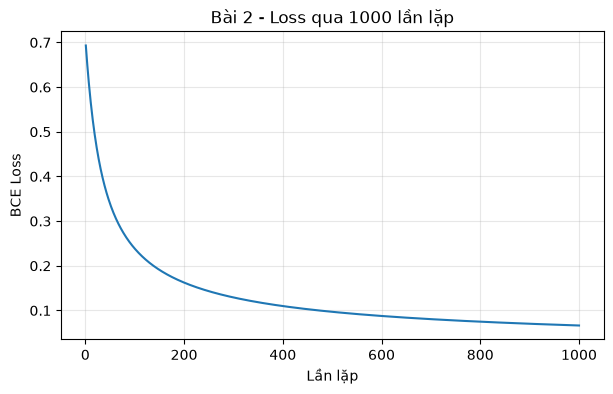

In [9]:
# Bài 2(j): huấn luyện 1000 vòng bằng NumPy, vẽ loss
w_long,b_long=0.0,0.0
loss_history=[]
for epoch in range(1000):
    z,p,loss,J,dw,db=metrics(xn,y_movie,w_long,b_long)
    loss_history.append(J)
    w_next=w_long-alpha*dw
    b_next=b_long-alpha*db
    w_long,b_long=w_next,b_next

print(f"w sau 1000 vòng={w_long:.6f}; b={b_long:.6f}")
print(f"Loss cuối trước cập nhật cuối={loss_history[-1]:.6f}")
print(f"Loss sau cập nhật cuối={metrics(xn,y_movie,w_long,b_long)[3]:.6f}")
print(f"Loss sau 2 bước={history2[2][2]:.6f}")
plt.figure(figsize=(7,4))
plt.plot(range(1,1001),loss_history)
plt.xlabel("Lần lặp"); plt.ylabel("BCE Loss")
plt.title("Bài 2 - Loss qua 1000 lần lặp"); plt.grid(True,alpha=.3); plt.show()


## Bài 3 — Đồ thị tính toán và lan truyền ngược
`J=3a+2(4b+5cd)`, với `a=2, b=3, c=4, d=5`.


In [10]:
# Bài 3(a,c): phân rã và forward pass
a,b,c,d=2.0,3.0,4.0,5.0
u1=3*a
u2=4*b
u3=c*d
u4=5*u3
u5=u2+u4
u6=2*u5
J=u1+u6
for name,value in [("u1=3a",u1),("u2=4b",u2),("u3=cd",u3),("u4=5u3",u4),
                   ("u5=u2+u4",u5),("u6=2u5",u6),("J=u1+u6",J)]:
    print(f"{name:12s} = {value:.6f}")


u1=3a        = 6.000000
u2=4b        = 12.000000
u3=cd        = 20.000000
u4=5u3       = 100.000000
u5=u2+u4     = 112.000000
u6=2u5       = 224.000000
J=u1+u6      = 230.000000


In [11]:
# Bài 3(d,e,f): backward pass và kiểm chứng khai triển
dJ_du1=1
dJ_du6=1
dJ_du5=dJ_du6*2
dJ_du2=dJ_du5
dJ_du4=dJ_du5
dJ_du3=dJ_du4*5
dJ_da=dJ_du1*3
dJ_db=dJ_du2*4
dJ_dc=dJ_du3*d
dJ_dd=dJ_du3*c
print("Gradient thủ công:")
print("dJ/da =",dJ_da," dJ/db =",dJ_db," dJ/dc =",dJ_dc," dJ/dd =",dJ_dd)
print("Khai triển: J=3a+8b+10cd")
print("Đạo hàm trực tiếp: dJ/da=3, dJ/db=8, dJ/dc=10d=",10*d,", dJ/dd=10c=",10*c)


Gradient thủ công:
dJ/da = 3  dJ/db = 8  dJ/dc = 50.0  dJ/dd = 40.0
Khai triển: J=3a+8b+10cd
Đạo hàm trực tiếp: dJ/da=3, dJ/db=8, dJ/dc=10d= 50.0 , dJ/dd=10c= 40.0


In [12]:
# Bài 3(g): một bước Gradient Descent alpha=0.01, cập nhật đồng thời
alpha3=0.01
a_new=a-alpha3*dJ_da
b_new=b-alpha3*dJ_db
c_new=c-alpha3*dJ_dc
d_new=d-alpha3*dJ_dd
J_new=3*a_new+2*(4*b_new+5*c_new*d_new)
print(f"a'={a_new:.6f}; b'={b_new:.6f}; c'={c_new:.6f}; d'={d_new:.6f}")
print(f"J ban đầu={J:.6f}; J sau cập nhật={J_new:.6f}; thay đổi={J_new-J:.6f}")


a'=1.970000; b'=2.920000; c'=3.500000; d'=4.600000
J ban đầu=230.000000; J sau cập nhật=190.270000; thay đổi=-39.730000


In [13]:
# Bài 3(h): PyTorch Autograd
# Nếu thiếu PyTorch: chạy `pip install torch` trong Anaconda Prompt rồi khởi động lại kernel.
import torch
a_t=torch.tensor(2.0,requires_grad=True)
b_t=torch.tensor(3.0,requires_grad=True)
c_t=torch.tensor(4.0,requires_grad=True)
d_t=torch.tensor(5.0,requires_grad=True)
J_t=3*a_t+2*(4*b_t+5*c_t*d_t)
J_t.backward()
print("J =",J_t.item())
print("dJ/da =",a_t.grad.item())
print("dJ/db =",b_t.grad.item())
print("dJ/dc =",c_t.grad.item())
print("dJ/dd =",d_t.grad.item())


J = 230.0
dJ/da = 3.0
dJ/db = 8.0
dJ/dc = 50.0
dJ/dd = 40.0
